## Problem Statement


You are a data scientist working for a sports analytics company. The dataset, named **"sports_league_data.csv"** includes a variety of attributes for players in the league. The columns in the dataset are as follows:

- **player_id:** A unique identifier for each player.
- **age:** Age of the player.
- **position:** The position the player typically plays in (e.g., Forward, Midfielder, Defender, Goalkeeper).
- **team:** The team the player belongs to.
- **games_played:** The total number of games played by the player in the season.
- **player_rating:** An overall performance rating for the player for the season.

**Import Necessary Libraries**

In [34]:
import pandas as pd 
import seaborn as sns
from matplotlib import pyplot as plt

## Task1

1. Import the data from the "sports_league_data.csv" file.
2. display the number of rows and columns. 
3. Display the first few rows of the dataset to get an overview.


In [35]:
df=pd.read_csv("sports_league_data.csv")
df.head()

,player_id,age,position,team,games_played,player_rating
0,P0001,34,Forward,Team 14,29,7.2
1,P0002,29,Defender,Team 15,27,8.3
2,P0003,31,Goalkeeper,Team 4,39,6.4
3,P0004,36,Goalkeeper,Team 6,35,6.6
4,P0005,34,Defender,Team 14,26,7.2


In [36]:
df.shape

(1000, 6)

## Task2:

**Age Analysis:**
- Mean: Calculate the average age of players in the league.
- Standard Deviation Intervals:
    - Calculate the age range within one standard deviation of the mean.
    - Calculate the age range within two standard deviations of the mean.
    - Calculate the age range within three standard deviations of the mean.
  

In [37]:
mean_age=round(df['age'].mean(),2)
std_age=round(df['age'].std(),2)
mean_age,std_age

(np.float64(26.85), 4.58)

In [38]:
left1=mean_age-std_age
right1=mean_age+std_age
left1,right1

(np.float64(22.270000000000003), np.float64(31.43))

In [39]:
left2=mean_age-2*std_age
right2=mean_age+2*std_age
left2,right2

(np.float64(17.69), np.float64(36.010000000000005))

In [40]:
left3=mean_age-3*std_age
right3=mean_age+3*std_age
left3,right3

(np.float64(13.110000000000001), np.float64(40.59))

## Task3:

**Player Rating Analysis:**
- Mean: Determine the average player rating across the league.
- Standard Deviation Intervals:
    - Calculate the player rating range within one standard deviation of the mean.
    - Calculate the player rating range within two standard deviations of the mean.
    - Calculate the player rating range within three standard deviations of the mean.

In [41]:
mean_rating=round(df['player_rating'].mean(),2)
std_rating=round(df['player_rating'].std(),2)
mean_rating,std_rating

(np.float64(6.56), 1.45)

In [42]:
df['player_rating'].describe()

count    1000.000000
mean        6.555300
std         1.454361
min         1.000000
25%         5.800000
50%         6.500000
75%         7.300000
max        15.000000
Name: player_rating, dtype: float64

## Task4:

Create histogram with Kernel Density Estimation (KDE) plots for both the 'age' and 'player_rating' columns from the dataset. While constructing these plots, ensure to visually represent the standard deviation intervals on the graph.


- **'age'**

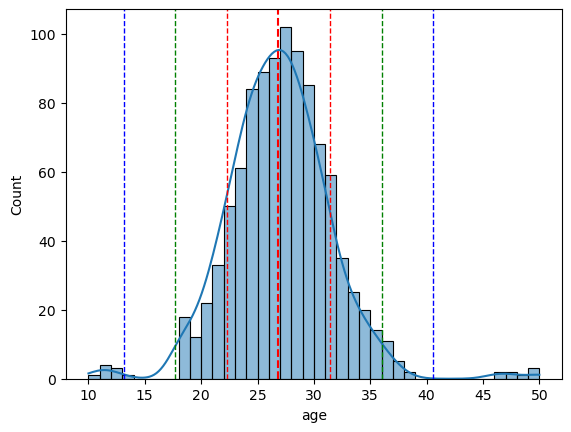

In [43]:
sns.histplot(df['age'],kde=True)
plt.axvline(mean_age, color='red', linestyle='--', label='Mean')

plt.axvline(mean_age + std_age, color='r', linestyle='dashed', linewidth=1)
plt.axvline(mean_age - std_age, color='r', linestyle='dashed', linewidth=1)

# two standard deviation
plt.axvline(mean_age + 2*std_age, color='g', linestyle='dashed', linewidth=1)
plt.axvline(mean_age - 2*std_age, color='g', linestyle='dashed', linewidth=1)

# three standard deviation
plt.axvline(mean_age + 3*std_age, color='b', linestyle='dashed', linewidth=1)
plt.axvline(mean_age - 3*std_age, color='b', linestyle='dashed', linewidth=1)

- **'player_rating'**

<Axes: xlabel='player_rating', ylabel='Count'>

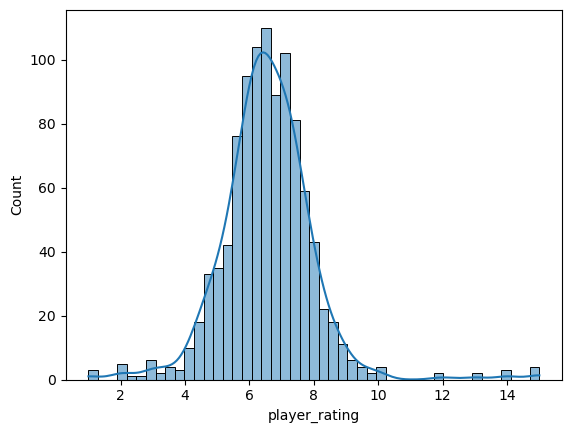

In [44]:
sns.histplot(df['player_rating'],kde=True)

## Task5

- Calculate the lower and upper boundaries for the 'Age' and 'Player_Rating' columns. 
- For each column, identify values that fall outside the calculated lower and upper boundaries. These values are considered outliers.

- **Display age outliers**

In [45]:
lower=mean_age-3*std_age
higher=mean_age+3*std_age

df[(df['age']<lower) & (df['age']>higher)]

,player_id,age,position,team,games_played,player_rating


In [46]:
df.dtypes

player_id         object
age                int64
position          object
team              object
games_played       int64
player_rating    float64
dtype: object

In [47]:
lower=int(mean_age-3*std_age)
higher=int(mean_age+3*std_age)

df[(df['age']<lower) | (df['age']>higher)]

,player_id,age,position,team,games_played,player_rating
66,P0067,11,Midfielder,Team 18,38,6.4
123,P0124,50,Midfielder,Team 11,23,5.9
156,P0157,46,Midfielder,Team 6,16,4.5
207,P0208,10,Forward,Team 15,30,6.0
305,P0306,47,Midfielder,Team 7,22,7.6
376,P0377,11,Defender,Team 16,25,6.1
474,P0475,50,Goalkeeper,Team 4,24,7.4
630,P0631,47,Defender,Team 16,28,6.0
647,P0648,12,Goalkeeper,Team 16,21,6.1
795,P0796,11,Goalkeeper,Team 8,33,7.5


- **Display player_rating outliers**

In [48]:
mean = int(df['player_rating'].mean()) 
std = int(df['player_rating'].std())

lower = mean - 3*std
upper = mean + 3*std

df[(df.player_rating<lower)|(df.player_rating>upper)]

,player_id,age,position,team,games_played,player_rating
32,P0033,23,Defender,Team 1,29,2.0
41,P0042,21,Goalkeeper,Team 19,27,13.0
96,P0097,27,Defender,Team 2,37,2.0
102,P0103,22,Defender,Team 1,31,2.7
108,P0109,35,Forward,Team 2,35,9.4
116,P0117,31,Goalkeeper,Team 19,25,2.1
185,P0186,21,Midfielder,Team 4,29,9.9
193,P0194,22,Defender,Team 11,26,9.5
194,P0195,29,Forward,Team 6,33,1.0
212,P0213,30,Defender,Team 7,26,15.0


## Task6

-  Remove outliers from both the 'age' and 'player_rating' columns and then visualize the adjusted data using histogram plots.


In [49]:
#1.remove outliers for age

mean = int(df['age'].mean()) 
std = int(df['age'].std())

lower = mean - 3*std
upper = mean + 3*std

df = df[(df.age>lower)&(df.age<upper)]


#2.remove outliers for player_rating
mean = round(df['player_rating'].mean(),1) 
std = round(df['player_rating'].std(), 1)

lower = mean - 3*std
upper = mean + 3*std

df = df[(df.player_rating>lower)&(df.player_rating<upper)]

- **plot the histograms**

<Axes: xlabel='age', ylabel='Count'>

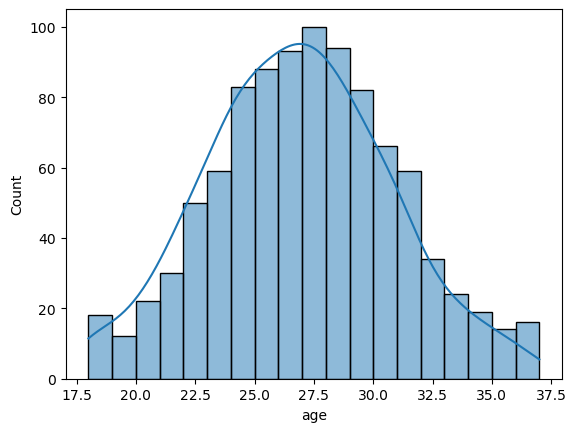

In [50]:
sns.histplot(df['age'],kde=True)

<Axes: xlabel='player_rating', ylabel='Count'>

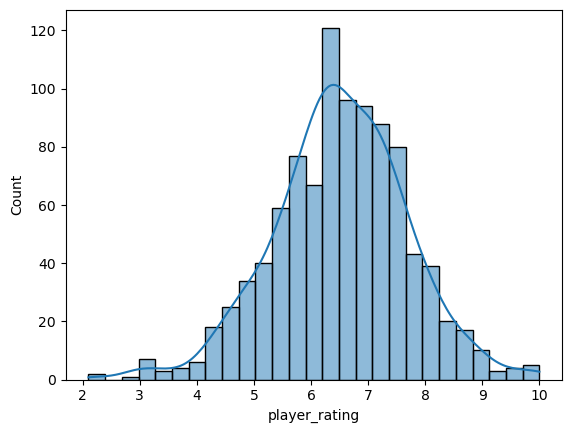

In [51]:
sns.histplot(df['player_rating'],kde=True)